# This file compares how Regularization works in ANN

- Regularization is used to prevent overfitting by adding a penalty to the loss function

- In this file I have created a dummy dataset with help of (make_moons) parameter
- The file is simple comparison of before regularization vs after applying regularization

In [2]:
# Import all libraries

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from mlxtend.plotting import plot_decision_regions  # used to visualize the decision boundaries of a machine learning classifier in 1D or 2D space.

import tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam

In [3]:
X, y = make_moons(100, noise=0.25, random_state=2)  # geenrating random dataset with help of make_moons 

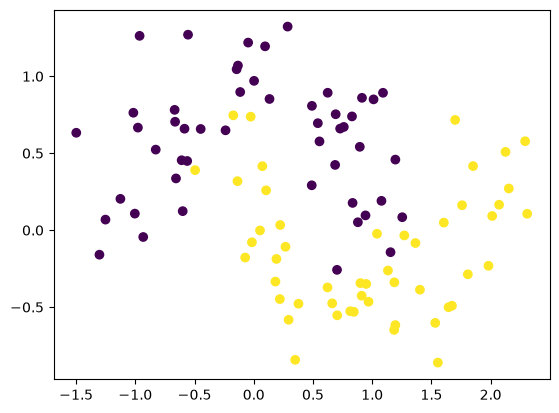

In [4]:
plt.scatter(X[:,0], X[:, 1], c=y)
plt.show()

# Train the model with Sequential

In [ ]:
model1 = Sequential()  

model1.add(Dense(128, input_dim=2, activation="relu"))
model1.add(Dense(128, activation="relu"))
model1.add(Dense(1,activation="sigmoid"))

model1.summary()



# Input:          2 values
#                   ↓
# Dense layer:    128 neurons + ReLU
#                   ↓
# Dense layer:    128 neurons + ReLU
#                   ↓
# Output:         1 neuron + Sigmoid probability

c:\Desktop\Desktop\Microsoft_AI_Engineering\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,025 (66.50 KB)

 Trainable params: 17,025 (66.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile with optimizer

adam = Adam(learning_rate=0.01)
model1.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])

history1 = model1.fit(X, y, epochs=200, validation_split=0.2, verbose=1)    # purposely training for large num of epochs for overfitting

Epoch 1/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 163ms/step - accuracy: 0.9625 - loss: 0.1167 - val_accuracy: 0.8500 - val_loss: 0.8433
Epoch 2/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9500 - loss: 0.1349 - val_accuracy: 0.9000 - val_loss: 0.8068
Epoch 3/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.9625 - loss: 0.0504 - val_accuracy: 0.9500 - val_loss: 0.2799
Epoch 4/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.9750 - loss: 0.0511 - val_accuracy: 0.9500 - val_loss: 0.0784
Epoch 5/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.9500 - loss: 0.1106 - val_accuracy: 0.9500 - val_loss: 0.2232
Epoch 6/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9875 - loss: 0.0366 - val_accuracy: 0.9500 - val_loss: 0.3787
Epoch 7/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9875 - loss: 0.0424 - val_accuracy: 0.9000 - val_loss: 0.5387
Epoch 8/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.9750 - loss: 0.0545 - val_accuracy: 0.9000 - val_loss

In [ ]:
class ModelWrapper:
    def predict(self, X):
        return (model1.predict(X, verbose=0) > 0.5).astype(int).ravel()


# so this class is build to convert prob vals to 0,1 

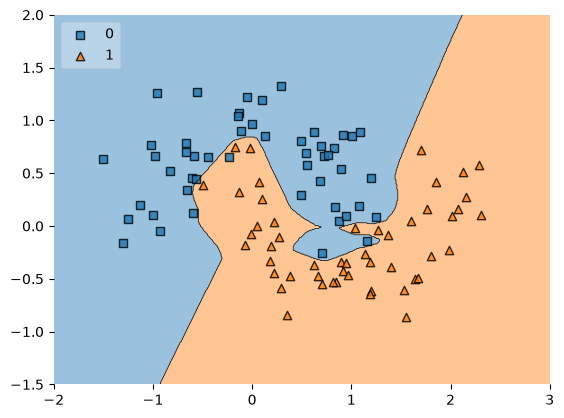

In [ ]:
plot_decision_regions(X, y, clf=ModelWrapper(), legend=2)   # plot_decision_regions() needs these final 0 and 1 labels, not probability values.
plt.xlim(-2,3)
plt.ylim(-1.5,2)
plt.show()


# this shows MOdel is trying to overfit 

C:\Users\rauts\AppData\Local\Temp\ipykernel_9756\3032606420.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc=2)


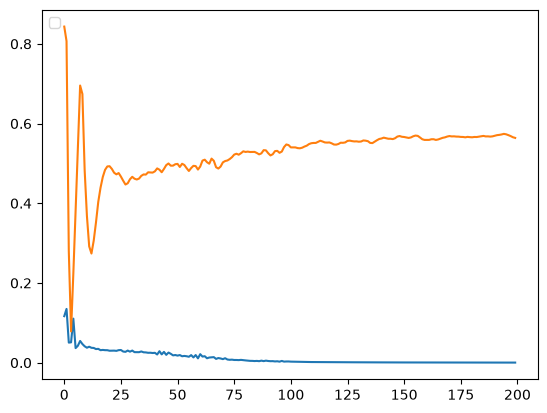

In [ ]:
# Plot the graph

plt.plot(history1.history['loss'])
plt.plot(history1.history['val_loss'])

# the graph shows the gap between test and train is high which shows a clear overfitting problem

# From below I used Regularization (L2) on the same dataset

In [21]:
model2 = Sequential()

model2.add(Dense(128, input_dim=2, activation="relu", kernel_regularizer=tensorflow.keras.regularizers.l2(0.03)))
model2.add(Dense(128, activation="relu", kernel_regularizer=tensorflow.keras.regularizers.l2(0.03)))
model2.add(Dense(1, activation='sigmoid'))

model2.summary()

c:\Desktop\Desktop\Microsoft_AI_Engineering\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,025 (66.50 KB)

 Trainable params: 17,025 (66.50 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
adam = Adam(learning_rate=0.01)
model2.compile(loss='binary_crossentropy',optimizer=adam, metrics=['accuracy'])

history2 = model2.fit(X, y, epochs=200, validation_split=0.2, verbose=1)

Epoch 1/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 362ms/step - accuracy: 0.6250 - loss: 4.0735 - val_accuracy: 0.8500 - val_loss: 2.7161
Epoch 2/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 211ms/step - accuracy: 0.7875 - loss: 2.3566 - val_accuracy: 0.9000 - val_loss: 1.5020
Epoch 3/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.8500 - loss: 1.3468 - val_accuracy: 0.9000 - val_loss: 0.8607
Epoch 4/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.8500 - loss: 0.8417 - val_accuracy: 0.9000 - val_loss: 0.5750
Epoch 5/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.8250 - loss: 0.6741 - val_accuracy: 0.9000 - val_loss: 0.5340
Epoch 6/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.8375 - loss: 0.6742 - val_accuracy: 0.9000 - val_loss: 0.6025
Epoch 7/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.8250 - loss: 0.6424 - val_accuracy: 0.9000 - val_loss: 0.5101
Epoch 8/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.8250 - loss: 0.6571 - val_accuracy: 0.9000 - val

In [25]:
class ModelWrapper2:
    def predict(self, X):
        return (model2.predict(X, verbose=0) > 0.5).astype(int).ravel()


# so this class is build to convert prob vals to 0,1 

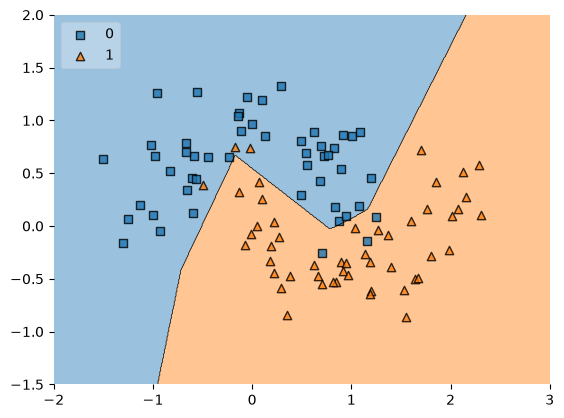

In [ ]:
# Agin plot the same graph

plot_decision_regions(X, y, clf=ModelWrapper2(), legend=2)
plt.xlim(-2,3)
plt.ylim(-1.5,2)
plt.show()


# As we can see the model tries to make overfitting less as possible -- we can imporve this by tweaking the Reguralization parameter

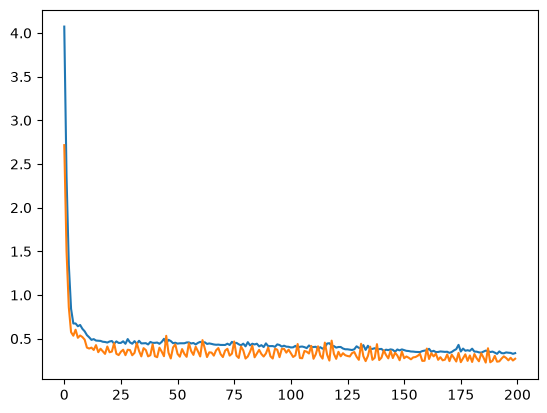

In [ ]:
plt.plot(history2.history['loss'])
plt.plot(history2.history['val_loss'])

# Compared from previous  graphs -- here the gap clearly decreases , which highlights the decrease in overfitting of the model